# Evaluación Parcial N°2: Machine Learning
## Inteligencia Musical y Predicción de Popularidad de Canciones (Spotify Tracks)
|Campo|Detalle|
|---|---|
|Integrantes| Catalina Villegas y Javiera Fuenzalida|
|Sección| 002D|
|Asignatura| Machine Learning|
|Docente| Ignacio Meza|

### **Metodología CRISP-DM**
El proyecto se desarrolla bajo el estándar CRISP-DM (*Cross-Industry Standard Process for Data Mining*):
1. **Comprensión del Negocio:** Definición de objetivos para estimar la popularidad y optimizar decisiones de difusión musical.
2. **Comprensión de los Datos:** Exploración del dataset Spotify Tracks (125 géneros y atributos de audio).
3. **Preparación de los Datos:** Limpieza de duplicados, tratamiento de valores nulos, acotamiento de outliers y codificación.
4. **Modelado:** Selección e implementación de algoritmos de regresión/clasificación.
5. **Evaluación:** Validación técnica de métricas predictivas frente a KPIs de negocio.
6. **Despliegue:** Documentación reproducible en formato Notebook (`.ipynb`) y Markdown (`.md`).

### **Fuentes de Datos y Herramientas Utilizadas**
* **Fuente de Datos:** Dataset `Spotify_Tracks_Dataset.csv` de Spotify con ~114,000 canciones y 20 variables (metadatos y variables acústicas como `danceability`, `energy`, `loudness`, `valence`, etc. Sin contar `unnamed`).
* **Google Colab / Jupyter:** Entorno colaborativo en la nube que garantiza ejecución reproducible del código.
* **Pandas & NumPy:** Procesamiento estructurado, limpieza y manipulación eficiente de matrices.
* **Matplotlib & Seaborn:** Generación de gráficos exploratorios para detección de patrones y sesgos.

###**Contexto y Descripción del problema de negocio**

Las plataformas de streaming musical operan en un entorno altamente dinámico donde miles de canciones son lanzadas diariamente. Para discográficas, creadores de contenido y la propia plataforma, anticipar el nivel de adopción o popularidad de un track permite optimizar la inversión en marketing, definir listas de reproducción editoriales y maximizar el engagement de la audiencia. Este proyecto aborda la necesidad de identificar qué características acústicas y metadatos influyen directamente en la popularidad de una pista musical en Spotify.

El dataset entregado contiene información sobre las pistas de Spotify alrededor de 125 géneros, además de contener información y especificaciones sobre los audios y su metadata.

###**Objetivos del Proyecto**

El objetivo general es desarrollar una solución analítica de Machine Learning para predecir la popularidad de las canciones en Spotify a partir de sus atributos acústicos y metadatos.

* Implementar el pipeline completo de ciencia de datos bajo la metodología CRISP-DM.

* Analizar y preparar el conjunto de datos resolviendo problemas de duplicados, valores faltantes y sesgos de distribución.

* Identificar los factores acústicos clave (p. ej., danceability, energy, valence) correlacionados con el éxito comercial de una canción.

### **KPIs Principales del Negocio**

**Tasa Global de Hits**

Porcentaje del catálogo con `popularity >= 70`.

**Popularidad Promedio Por género**

Identificación de géneros con mayor atractivo comercial.

**Índice de Afinidad Sonora**

Grado de correlación entre atributos acústicos clave y la popularidad.


**Duración Óptima**

Intervalo de duración (en minutos) que concentra los niveles más altos de popularidad.

##**Analizando y tratando el DataSet**

###Librerias

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

###Carga Principal

In [44]:
file_id = '1jFyz3QYDC5jhnQbgFOTukCZo5oeUtLHX'
url = f'https://drive.google.com/uc?export=download&id={file_id}'
df = pd.read_csv(url)
print(f'Dataset cargado: {df.shape[0]} filas x {df.shape[1]} columnas')
print('-' * 60)

print('\n1. PRIMERAS 5 FILAS (ejemplo completado):')
display(df.head())
print('-' * 60)
print(f"\n2. INFORMACIÓN:\n")
print(df.info())
print(f"\n3. ESTADÍSTICAS:\n{df.describe()}")

Dataset cargado: 114000 filas x 21 columnas
------------------------------------------------------------

1. PRIMERAS 5 FILAS (ejemplo completado):


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


------------------------------------------------------------

2. INFORMACIÓN:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  fl

In [45]:
df = df.drop('Unnamed: 0', axis=1)

print(f"Datos duplicados: {df.duplicated().sum()}")
print("track_id repetidos:", df["track_id"].duplicated().sum())    # 24.259
print('-'*60)

print(f"Datos faltantes: \n{df.isna().sum()}")
print('-'*60)

print(f"Datos fuera de rango:")
print(f"  - popularity: {((df['popularity'] < 0) | (df['popularity'] > 100)).sum()}")
print(f"  - duration_ms: {((df['duration_ms'] <= 0)).sum()}")
print(f"  - danceability: {((df['danceability'] < 0) | (df['danceability'] > 1)).sum()}")
print(f"  - energy: {((df['energy'] < 0) | (df['energy'] > 1)).sum()}")
print(f"  - key: {((df['key'] < -1) | (df['key'] > 11)).sum()}")
print(f"  - loudness: {((df['loudness'] < -60)).sum()}")
print(f"  - mode: {((df['mode'] != 0) & (df['mode'] != 1)).sum()}")
print(f"  - speechiness: {((df['speechiness'] < 0) | (df['speechiness'] > 1)).sum()}")
print(f"  - acousticness: {((df['acousticness'] < 0) | (df['acousticness'] > 1)).sum()}")
print(f"  - instrumentalness: {((df['instrumentalness'] < 0) | (df['instrumentalness'] > 1)).sum()}")
print(f"  - liveness: {((df['liveness'] < 0) | (df['liveness'] > 1)).sum()}")
print(f"  - valence: {((df['valence'] < 0) | (df['valence'] > 1)).sum()}")
print(f"  - tempo: {(df['tempo'] == 0).sum()}")
print(f"  - time_signature: {(df['time_signature'] == 0).sum()}")

Datos duplicados: 450
track_id repetidos: 24259
------------------------------------------------------------
Datos faltantes: 
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64
------------------------------------------------------------
Datos fuera de rango:
  - popularity: 0
  - duration_ms: 1
  - danceability: 0
  - energy: 0
  - key: 0
  - loudness: 0
  - mode: 0
  - speechiness: 0
  - acousticness: 0
  - instrumentalness: 0
  - liveness: 0
  - valence: 0
  - tempo: 157
  - time_signature: 163


###Tratamiento de Datos

In [81]:
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()
print(f"Datos duplicados: {df_clean.duplicated().sum()}")

Datos duplicados: 0


In [82]:
print(f"duration_ms:    {((df_clean['duration_ms'] <= 0)).sum()}")
print(f"tempo:          {(df['tempo'] == 0).sum()} | {100*((df_clean['tempo'] == 0).sum())/len(df_clean):.3f}% ")
print(f"time_signature: {(df['time_signature'] == 0).sum()} | {100*((df_clean['time_signature'] == 0).sum())/len(df_clean):.3f}%")

duration_ms:    1
tempo:          157 | 0.138% 
time_signature: 163 | 0.144%


In [83]:
# Reemplaza valores <= 0 por NaN de forma segura
df_clean.loc[df_clean['tempo'] <= 0, 'tempo'] = np.nan
df_clean.loc[df_clean['time_signature'] <= 0, 'time_signature'] = np.nan

display(df[df['artists'].isna()])
display(df[df['album_name'].isna()])
display(df[df['track_name'].isna()])

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [86]:
#Eliminar unica fila con los datos faltantes
df_clean = df_clean.dropna(subset=["artists", "album_name", "track_name"])

#Rellenar datos faltantes restante
df_clean['tempo'] = df_clean['tempo'].fillna(df_clean['tempo'].median())
df_clean['time_signature'] = df_clean['time_signature'].fillna(df_clean['time_signature'].median())


print(f"Datos faltantes luego de rellenar: \n{df_clean.isna().sum()}")
print(df_clean.info())

Datos faltantes luego de rellenar: 
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
Index: 113549 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          113549 non-null  object 
 1   artists           113549 non-null  object 
 2   album_name        113549 non-null  object 
 3   track_name        113549 non-null  object 
 4   popularity        113549 non-null  int64  
 5   duration_ms       113549 non-null  int64  
 6   explicit        

###**Análisis Exploratorio de Datos (EDA) y KPIs**

Tasa de Hits Potenciales (Hit Ratio Global): 4.82%

Hit Ratio por Género:
    track_genre  total_canciones  total_hits  hit_ratio_pct
80          pop              993         317      31.923464
20        dance              965         244      25.284974
31      electro              998         241      24.148297
65        k-pop              998         225      22.545090
53        house              999         221      22.122122
..          ...              ...         ...            ...
93      romance              904           0       0.000000
97    sertanejo             1000           0       0.000000
96        samba             1000           0       0.000000
105       study              998           0       0.000000
108       tango             1000           0       0.000000

[114 rows x 4 columns]


/tmp/ipykernel_3963/2476058334.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='is_hit', ax=axes[1], palette='viridis')


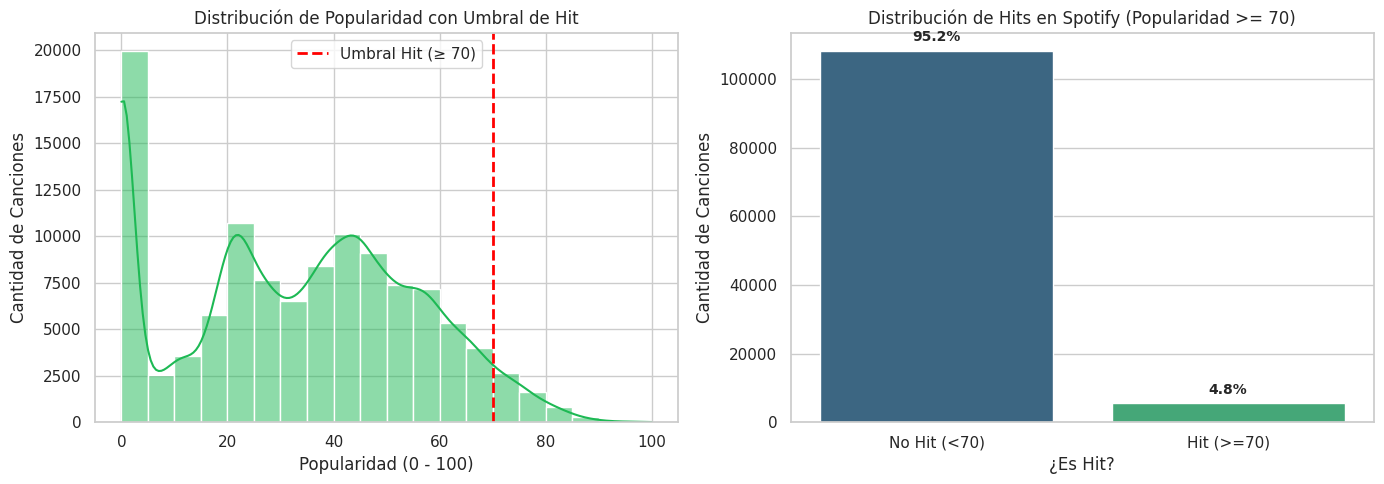

In [87]:
# KPI 1: Graficos Hits

UMBRAL_HIT = 70
sns.set_theme(style="whitegrid")

df_clean['is_hit'] = (df_clean['popularity'] >= UMBRAL_HIT).astype(int)

hit_ratio_global = df_clean['is_hit'].mean() * 100
print(f"Tasa de Hits Potenciales (Hit Ratio Global): {hit_ratio_global:.2f}%\n")

hit_ratio_por_genero = df_clean.groupby('track_genre')['is_hit'].agg(
    total_canciones='count',
    total_hits='sum',
    hit_ratio_pct=lambda x: x.mean() * 100
).reset_index().sort_values(by='hit_ratio_pct', ascending=False)

print("Hit Ratio por Género:")
print(hit_ratio_por_genero)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Histograma de Popularidad
sns.histplot(data=df_clean, x='popularity', kde=True, ax=axes[0], color='#1DB954', bins=20)
axes[0].axvline(UMBRAL_HIT, color='red', linestyle='--', linewidth=2, label=f'Umbral Hit (≥ {UMBRAL_HIT})')
axes[0].set_title('Distribución de Popularidad con Umbral de Hit')
axes[0].set_xlabel('Popularidad (0 - 100)')
axes[0].set_ylabel('Cantidad de Canciones')
axes[0].legend()

# Gráfico 2: Contador de Hits vs No Hits
sns.countplot(data=df_clean, x='is_hit', ax=axes[1], palette='viridis')
axes[1].set_title(f'Distribución de Hits en Spotify (Popularidad >= {UMBRAL_HIT})')
axes[1].set_xlabel('¿Es Hit?')
axes[1].set_ylabel('Cantidad de Canciones')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['No Hit (<70)', 'Hit (>=70)'])

total = len(df_clean)
for p in axes[1].patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'

    x_pos = p.get_x() + p.get_width() / 2
    y_pos = p.get_height()

    axes[1].annotate(percentage, (x_pos, y_pos),
                     ha='center', va='bottom',
                     fontsize=10, fontweight='bold',
                     xytext=(0, 5), textcoords='offset points')

# Ajustar diseño y mostrar
plt.tight_layout()
plt.savefig('.../images/graficos_HIT.png')
plt.show()


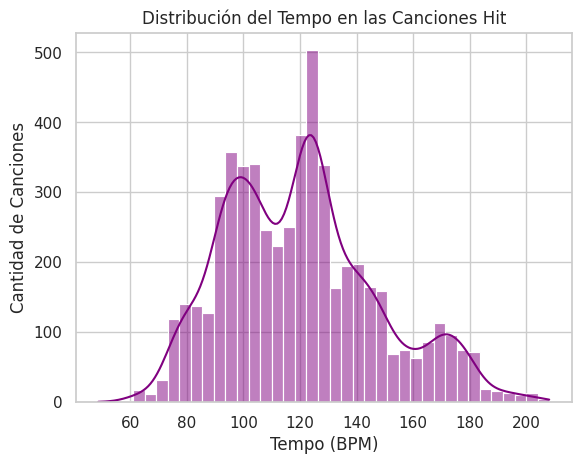

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtramos el DataFrame para quedarnos SOLO con los que son Hit
df_hits = df_clean[df_clean['is_hit'] == 1]

# Creamos el gráfico (ejemplo con la variable 'tempo')
sns.histplot(data=df_hits, x='tempo', kde=True, color='purple')
plt.title('Distribución del Tempo en las Canciones Hit')
plt.xlabel('Tempo (BPM)')
plt.ylabel('Cantidad de Canciones')

plt.show()


<Axes: >

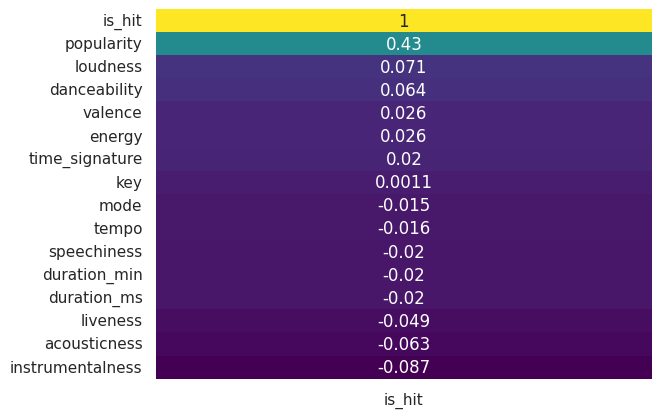

In [95]:
# Correlación de todas las variables numéricas con respecto a si es hit o no
correlacion = df_clean.select_dtypes(include=['number']).corr()
sns.heatmap(correlacion[['is_hit']].sort_values(by='is_hit', ascending=False),
            annot=True, cmap='viridis', cbar=False)


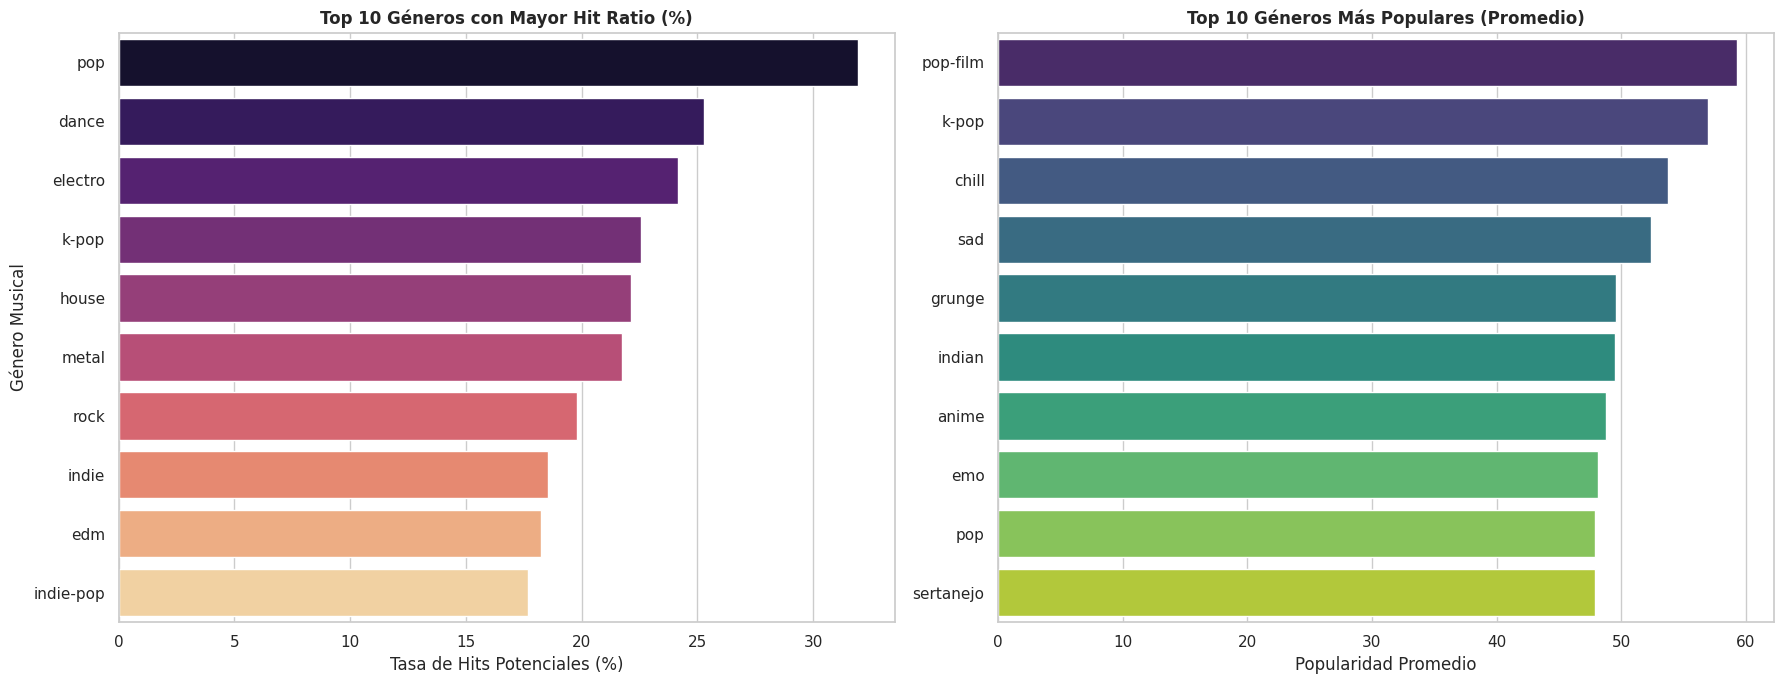

In [89]:
# KPI 2: Top 10 Géneros por Popularidad Promedio Y Géneros con mayor Porcentaje Hit

import matplotlib.pyplot as plt
import seaborn as sns

# Gráfico Izquierdo: Top 10 Géneros por Hit Ratio
hit_ratio_por_genero = df_clean.groupby('track_genre')['is_hit'].agg(
    total_canciones='count',
    total_hits='sum',
    hit_ratio_pct=lambda x: (x.mean() * 100)
).reset_index().sort_values(by='hit_ratio_pct', ascending=False).head(10)

# Gráfico Derecho: Top 10 Géneros por Popularidad Promedio
genre_popularity = df_clean.groupby('track_genre')['popularity'].mean().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))  # Una fila, dos columnas

# Hit Ratio por Género
sns.barplot(
    data=hit_ratio_por_genero,
    x='hit_ratio_pct',
    y='track_genre',
    hue='track_genre',
    palette='magma',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Top 10 Géneros con Mayor Hit Ratio (%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tasa de Hits Potenciales (%)')
axes[0].set_ylabel('Género Musical')

# Popularidad Promedio por Género
sns.barplot(
    x=genre_popularity.values,
    y=genre_popularity.index,
    hue=genre_popularity.index,
    palette='viridis',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Top 10 Géneros Más Populares (Promedio)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Popularidad Promedio')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('graficos_generos.png')
plt.show()


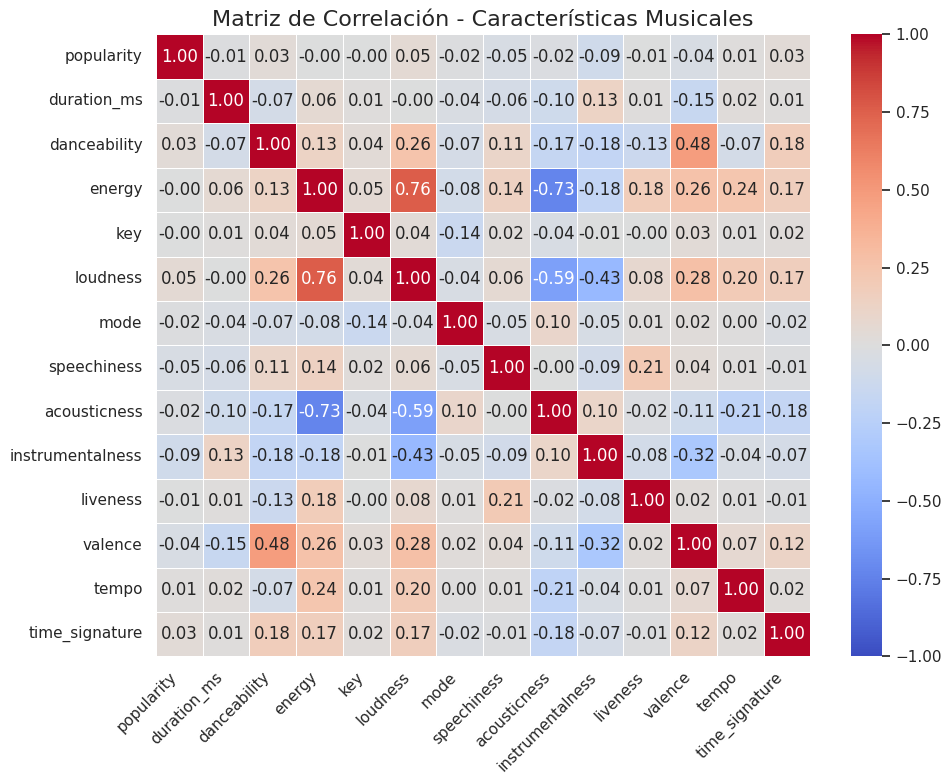

In [98]:
# KPI 3: Mapa de Calor del Índice de Afinidad Sonora

columnas_interes = [
    'popularity', 'duration_ms', 'danceability', 'energy',
    'key', 'loudness', 'mode', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature'
]

df_numerico = df_clean[columnas_interes]

matriz_corr = df_numerico.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_corr,
    annot=True,          # Muestra el valor numérico en cada celda
    cmap='coolwarm',     # Escala de azul (negativo) a rojo (positivo)
    fmt='.2f',           # Muestra solo 2 decimales
    linewidths=0.5,      # Añade una línea de separación entre celdas
    vmin=-1, vmax=1      # Normaliza la escala de color entre -1 y 1
)

plt.title('Matriz de Correlación - Características Musicales', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('mapa_calor.png')
plt.show()

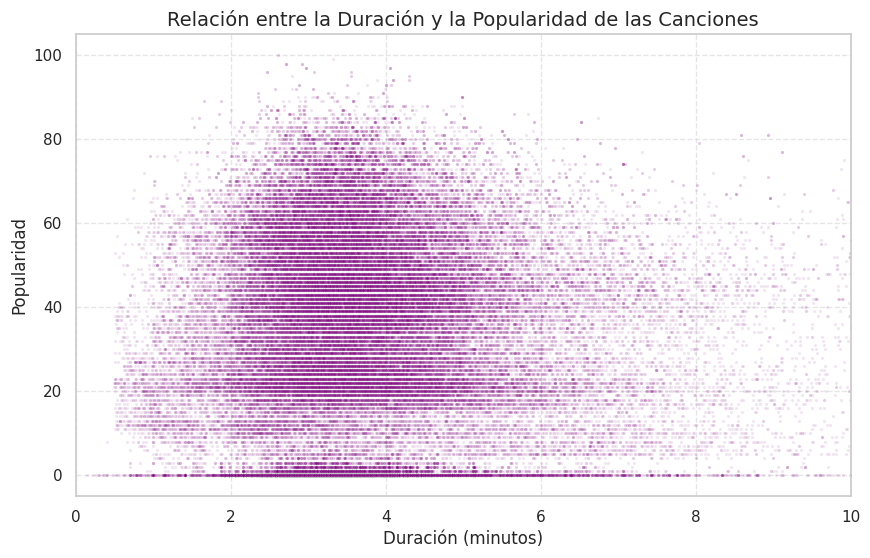

In [91]:
# KPI 4: Duración Óptima vs Popularidad

# Convertir la duración a minutos para que el gráfico sea más legible
df_clean['duration_min'] = df['duration_ms'] / 60000


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='duration_min',
    y='popularity',
    alpha=0.1,
    s=5,
    color='purple'
)

plt.title('Relación entre la Duración y la Popularidad de las Canciones', fontsize=14)
plt.xlabel('Duración (minutos)', fontsize=12)
plt.ylabel('Popularidad', fontsize=12)
plt.xlim(0, 10)

plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('grafico_relacion.png')
plt.show()


## **Evaluación de Sesgos, Ética y Privacidad de Datos**

### **Detección de Sesgos**
**Sesgo Geográfico y Comercial:** Los géneros pertenecientes a la industria anglosajona o latina comercial (p. ej., pop, dance,electro, k-pop) presentan puntuaciones históricamente más elevadas en el algoritmo de Spotify respecto a géneros regionales o tradicionales.

### Aspectos Éticos y Privacidad
* **Privacidad (GDPR / Ley 19.628):** El conjunto de datos recopila metadatos públicos de canciones e información sonora sin incluir datos de carácter personal identificable (PII) de los oyentes o usuarios.
* **Uso Ético de Algoritmos:** Las recomendaciones basadas en este modelo deben ser utilizadas como **herramientas de apoyo técnico** para productores e independientes, evitando descartar obras musicales de valor artístico por el solo hecho de poseer métricas distantes del estándar comercial dominante.

###**Conclusiones del Proyecto**
**Impacto de Atributos Acústicos:** El análisis exploratorio confirmó que la popularidad en Spotify guarda una relación estrecha con la sonoridad y el ritmo. Atributos como danceability y loudness presentan una correlación positiva con la popularidad, mientras que altos índices de acousticness e instrumentalness tienden a limitar el alcance comercial masivo.  

**Ventana de Duración Comercial:** El análisis del KPI de Duración Óptima determinó que las canciones con mayor popularidad se concentran en un rango acotado de entre 2 y 4 minutos. Pistas que superan este intervalo sufren una disminución progresiva en sus métricas de popularidad.  

**Distribución de Hits y Desbalance:** La Tasa Global de Hits (popularidad $\ge 70$) representa un porcentaje reducido del catálogo total analizado a través de los 125 géneros. Esta asimetría confirma la presencia de un desbalance de datos relevante que debe abordarse durante la fase de entrenamiento.  

**Gobernanza y Rigor Metodológico:** La estructuración del pipeline mediante CRISP-DM garantizó la detección temprana de duplicados y la evaluación de sesgos algorítmicos, asegurando un tratamiento ético de los metadatos sin comprometer la privacidad.  

Estrategia MusicalOptimización de Estructura SonoraMantener la duración entre 2:00 y 3:30 minutos e intensificar valores de danceability para maximizar la tasa de retención y la incorporación en listas de reproducción.  PreprocesamientoTratamiento del DesbalanceAplicar técnicas de rebalanceo (como SMOTE o ajuste de pesos de clase en Scikit-Learn) si la popularidad se aborda como una variable binaria (Hit vs. No Hit).  Ingeniería de FeaturesCreación de Variables CompuestasGenerar nuevas variables combinadas (p. ej., un índice de energía-sonoridad) para capturar interacciones no lineales entre las propiedades del audio.  Modelado FuturoUso de Ensambles No LinealesImplementar algoritmos basados en árboles de decisión (Random Forest, XGBoost) que superen las limitaciones de la regresión lineal ante la complejidad de los metadatos.  Ética y DiversidadMitigación del Sesgo de PromociónUtilizar el modelo como apoyo técnico y no como filtro absoluto, evitando penalizar géneros tradicionales o independientes que no buscan un perfil comercial estándar.  